# 2. Success measures: how would we know it is getting better?

Leadership tracks one number, open tickets. This notebook looks at why that number on its own is a weak
target, and proposes a small set of measures to follow each week.

## Setting up

Same setup as notebook 1.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../backend/data/rideops_support_tickets.csv")

for col in ["created_at", "first_response_at", "first_closed_at", "final_closed_at"]:
    df[col] = pd.to_datetime(df[col])

# The data was pulled at the end of 30 Sep 2026. We treat that as "now".
now = pd.Timestamp("2026-09-30 23:59")

df["escalated"] = df["escalated_to_eng"] == "Yes"
df["is_open"] = df["status"] != "Closed"
df["reopened"] = df["reopen_count"] > 0

# "Bounced" = sent to engineering, but engineering did not fix it
df["eng_outcome"] = df["eng_outcome"].fillna("")
df["bounced"] = df["escalated"] & (df["eng_outcome"] != "Fixed")

df["hours_to_close"] = (df["final_closed_at"] - df["created_at"]).dt.total_seconds() / 3600

end_time = df["final_closed_at"].fillna(now)
df["age_hours"] = (end_time - df["created_at"]).dt.total_seconds() / 3600

# Replace numbers with N, so similar problems get the same name
df["issue_type"] = df["description"].str.replace(r"\d+", "N", regex=True)

print("Tickets:", len(df))

Tickets: 1444


## What is actually in the open pile?

An open ticket is not automatically a problem. One raised an hour ago is open too.

In [2]:
open_now = df[df["is_open"]]
old_open = open_now[open_now["age_hours"] >= 48]
new_open = open_now[open_now["age_hours"] < 48]

print("Open tickets now:", len(open_now))
print("Open for more than 48 hours:", len(old_open))
print("Open for less than 48 hours:", len(new_open))
print()
print("Of the old ones, how many went to engineering:", (old_open["eng_handoffs"] > 0).sum())

Open tickets now: 48
Open for more than 48 hours: 25
Open for less than 48 hours: 23

Of the old ones, how many went to engineering: 24


Of the 48 open tickets, 25 have been open for more than 48 hours and 23 are newer than that. All but one
of the 25 older ones have been to engineering.

The newer ones are ordinary work in progress. The older ones are the real backlog, so those are what I
would count.

There is a second reason not to target the raw number. It goes down if tickets are closed early, and
notebook 1 showed one agent already doing that.

## Is 48 hours a reasonable line?

A check against how long tickets normally take.

In [3]:
support_only = df[~df["escalated"]]["hours_to_close"].dropna()
with_engineering = df[df["escalated"]]["hours_to_close"].dropna()

print("Tickets solved by support alone:")
print("  half are closed within", round(support_only.median(), 1), "hours")
print("  closed within 48 hours:", round((support_only <= 48).mean() * 100), "%")
print()
print("Tickets sent to engineering:")
print("  closed within 48 hours:", round((with_engineering <= 48).mean() * 100), "%")

Tickets solved by support alone:
  half are closed within 12.6 hours
  closed within 48 hours: 92 %

Tickets sent to engineering:
  closed within 48 hours: 20 %


92% of the tickets that support solves alone are closed within 48 hours. Only 20% of escalated tickets
are. So "older than 48 hours" is a fair marker for a ticket that is stuck.

## The measures I would track

| Role | Measure | Today | Why |
|---|---|---|---|
| Headline | Open tickets older than 48 hours | 25 | This is what clients feel |
| Driver | Share of escalations that come back unfixed | 57% | The root of the problem |
| Driver | Tickets with two or more trips to engineering | 229 in three months | Each trip costs about two days |
| Guardrail | Share of tickets reopened by clients | 10.5% | Must not rise, or we are only closing early |
| Guardrail | Average client rating | 3.70 | Must not fall |

The two guardrails are there so the headline number cannot be improved in a way that hurts clients.

## The same measures, week by week

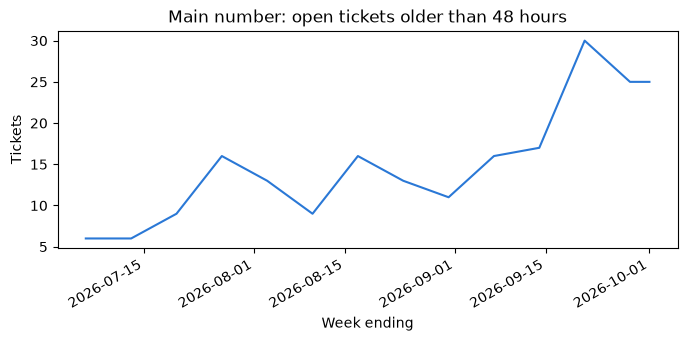

In [4]:
# For each Monday, count the tickets that were open at that moment
week_ends = list(pd.date_range("2026-07-06", "2026-09-28", freq="7D")) + [now]

rows = []
for day in week_ends:
    created_before = df["created_at"] < day
    not_closed_yet = df["final_closed_at"].isna() | (df["final_closed_at"] >= day)
    open_then = df[created_before & not_closed_yet]

    hours_open = (day - open_then["created_at"]).dt.total_seconds() / 3600
    older_than_48h = open_then[hours_open >= 48]

    rows.append({"week_end": day, "open": len(open_then), "open_over_48h": len(older_than_48h)})

backlog = pd.DataFrame(rows)

backlog.plot(x="week_end", y="open_over_48h", color="#2a78d6", legend=False,
             title="Main number: open tickets older than 48 hours", figsize=(8, 3.2))
plt.xlabel("Week ending")
plt.ylabel("Tickets")
plt.show()

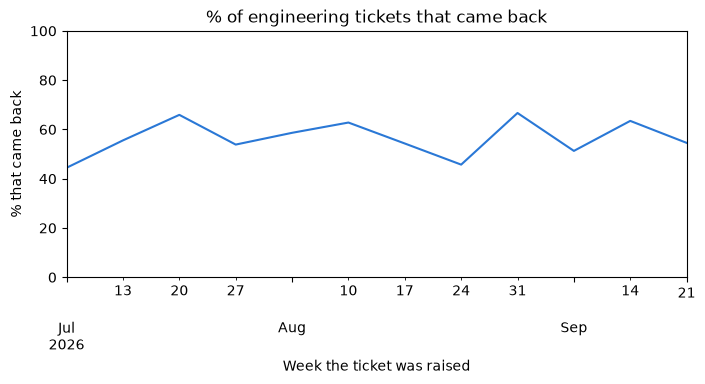

,new_tickets,two_or_more_trips,reopened_rate,average_rating,came_back_rate
week,,,,,
2026-07-06,87,10,0.13,3.73,0.44
2026-07-13,87,12,0.07,3.86,0.56
2026-07-20,97,27,0.05,3.68,0.66
2026-07-27,88,16,0.17,3.44,0.54
2026-08-03,107,13,0.11,3.86,0.59
2026-08-10,103,25,0.09,3.63,0.63
2026-08-17,117,17,0.10,3.95,0.54
2026-08-24,114,13,0.06,3.66,0.46
2026-08-31,105,18,0.15,3.46,0.67


In [5]:
# Put each ticket in the week it was raised (weeks start on Monday)
df["week"] = df["created_at"].dt.to_period("W").dt.start_time

df["two_or_more_trips"] = df["eng_handoffs"] >= 2

weekly = df.groupby("week").agg(
    new_tickets=("ticket_id", "count"),
    two_or_more_trips=("two_or_more_trips", "sum"),
    reopened_rate=("reopened", "mean"),
    average_rating=("csat_score", "mean"),
)
weekly["came_back_rate"] = df[df["escalated"]].groupby("week")["bounced"].mean()

# The first and last weeks are not full weeks, so we leave them out
weekly = weekly.iloc[1:-1]

(weekly["came_back_rate"] * 100).plot(color="#2a78d6", figsize=(8, 3.2),
                                      title="% of engineering tickets that came back")
plt.ylim(0, 100)
plt.xlabel("Week the ticket was raised")
plt.ylabel("% that came back")
plt.show()
weekly.round(2)

The headline measure climbs across the three months, which matches the complaint. It is also noisy from
week to week: the last four weekly readings were 16, 17, 30 and 25.

The return rate does not climb. It is high in every week, between 44% and 67%, with no trend. The
handover was leaking from the start, and as volume grew, the same leak produced a bigger pile.

## Baseline

Today's value for each measure, to compare against later.

In [6]:
sent_to_eng = df[df["escalated"]]

print("Open tickets older than 48 hours:", len(old_open))
print("Engineering tickets that came back:", round(sent_to_eng["bounced"].mean() * 100, 1), "%")
print("Tickets with 2+ trips, per week:", round(weekly["two_or_more_trips"].mean(), 1))
print("Tickets reopened by clients:", round(df["reopened"].mean() * 100, 1), "%")
print("Average client rating:", round(df["csat_score"].mean(), 2))

Open tickets older than 48 hours: 25
Engineering tickets that came back: 56.6 %
Tickets with 2+ trips, per week: 18.0
Tickets reopened by clients: 10.5 %
Average client rating: 3.7


## Proposed targets for four weeks

The data gives today's numbers. The targets below are my suggestion: they are what we would see if the
check prevents half of the returns it is able to prevent (notebook 3). They are something to agree with
the team, not a promise.

| Measure | Today | Target | Where it comes from |
|---|---|---|---|
| Open tickets older than 48 hours | 25 | about 18, at today's volume | Notebook 3 gives 18.5 if half are prevented |
| Escalations that come back | 57% | under 40% | The same case gives about 38% |
| Tickets with two or more trips, per week | about 18 | about 11 | Most multi-trip tickets are returns the check can prevent |
| Tickets reopened | 10.5% | not higher | Guardrail |
| Client rating | 3.70 | not lower | Guardrail |

In [7]:
# Where the targets come from: what if the check stops half of the returns it can stop?
support_can_solve = sent_to_eng["eng_outcome"].isin(["Config issue - returned to L1", "Not a bug - how-to"])
one_clean_trip = sent_to_eng["eng_outcome"].isin(["Insufficient info - returned to L1", "Not reproducible"])
can_stop = support_can_solve | one_clean_trip

# Tickets support solves are no longer sent to engineering at all
still_sent = len(sent_to_eng) - 0.5 * support_can_solve.sum()
still_come_back = sent_to_eng["bounced"].sum() - 0.5 * can_stop.sum()
print("Came back rate if half are stopped:", round(still_come_back / still_sent * 100), "%")

multi_trip = sent_to_eng[sent_to_eng["eng_handoffs"] >= 2]
can_stop_multi = can_stop[multi_trip.index].sum()
print("Multi-trip tickets:", len(multi_trip), "- of these the check can stop:", can_stop_multi)
per_week_now = weekly["two_or_more_trips"].mean()
print("2+ trip tickets per week if half are stopped:",
      round(per_week_now * (1 - 0.5 * can_stop_multi / len(multi_trip)), 1))

Came back rate if half are stopped: 38 %
Multi-trip tickets: 229 - of these the check can stop: 179
2+ trip tickets per week if half are stopped: 11.0


## How I would judge a four-week pilot

A move from 25 to 18 in the headline measure sits inside its normal weekly swing, and volume is still
growing, so the starting point will not be 25 in four weeks' time. The count is better read as a share
of the week's new tickets.

I would judge the pilot mainly on the return rate, pooled over the four weeks. That is about 170
escalations, enough for a fall from 57% to under 40% to be clear, where a single week of about 40 is
not.

The return rate is a late signal, because the outcome is only known once engineering answers. The early
signal is in the tool's own log: the share of escalations sent with gaps in the checklist.